# 11 · Causal inference basics

The question behind the challenge is causal in spirit: *are communities that are tribal / rural / climate-vulnerable less well mapped **because** of who they are?* A regression coefficient cannot answer that on its own.

**Running example (observational):** treatment `T = tribal tract` (874 of 9,794 tracts, 92% in Oklahoma), outcomes `y_poi` (log POIs per 100 buildings) and `no_fire`. **Caveat:** tribal status is not randomly assigned and the observed confounders are limited, so every estimate below is *conditional on the assumptions stated*, not a proven causal effect. Simulations with known truth are used wherever we need to show that a method works.

Needs `model_frame.parquet` from notebook 06.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name in ("notebooks", "analysis_scripts") else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
import networkx as nx
from sklearn.linear_model import LogisticRegression

## 1 · Causal inference vs traditional analytics, and the ladder of causation

| Rung (Pearl) | Question | Example here | Tool |
|---|---|---|---|
| 1 Association (seeing) | What is P(Y given T)? | Do tribal tracts have fewer POIs per building? | regression, correlation |
| 2 Intervention (doing) | What is P(Y given do(T))? | If a tract were tribal, what would its POI density be? | adjustment, IPW, RCT |
| 3 Counterfactual (imagining) | What *would have* happened to *this* tract otherwise? | Would tract X have had a fire station if it were not tribal? | structural causal model |

Traditional analytics stays on rung 1. Moving up requires **assumptions about how the data were generated** (a causal DAG), not just more data.

## 2 · Simpson's paradox
A trend that holds in every subgroup can reverse in the pooled data when a confounder is unevenly distributed.

pooled diff : -2.64
within-group: {0: 0.96, 1: 0.96} (truth = +1)

real data, share of tracts with NO fire POI
pooled   : non-tribal 0.719  tribal 0.571  gap -0.148
urban    : non-tribal 0.765  tribal 0.735  gap -0.030
rural    : non-tribal 0.476  tribal 0.394  gap -0.081


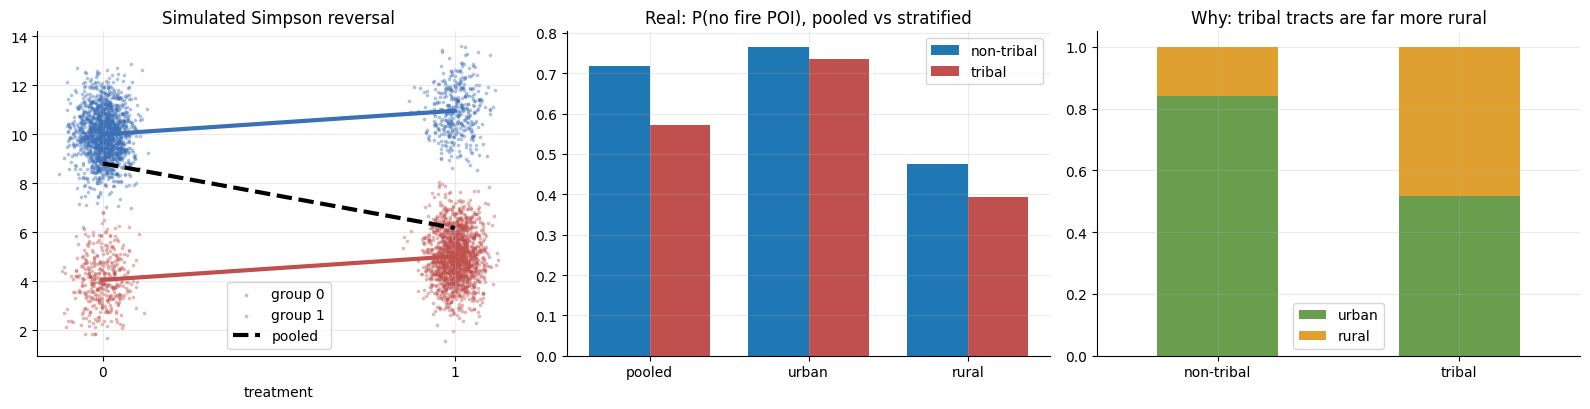

In [2]:
# (a) Classic reversal, simulated so the truth is known: treatment helps in both groups (+1), yet pooled data say it hurts.
n = 4000; g = rng.random(n) < .5                          # g = "hard case" group
t = np.where(g, rng.random(n) < .8, rng.random(n) < .2)    # hard cases are treated more often
y = 10 - 6 * g + 1.0 * t + rng.normal(0, 1, n)
sim = pd.DataFrame({"g": g.astype(int), "t": t.astype(int), "y": y})
print("pooled diff :", round(sim[sim.t == 1].y.mean() - sim[sim.t == 0].y.mean(), 2))
print("within-group:", sim.groupby("g").apply(lambda d: d[d.t == 1].y.mean() - d[d.t == 0].y.mean()).round(2).to_dict(), "(truth = +1)")
# (b) Real data: confounding by rurality changes the size of the tribal gap in P(no fire POI)
real = f.dropna(subset=["no_fire"]).copy()
pooled = real.groupby("tribal").no_fire.mean(); strat = real.groupby(["rural", "tribal"]).no_fire.mean().unstack()
print("\nreal data, share of tracts with NO fire POI")
print(f"pooled   : non-tribal {pooled[0]:.3f}  tribal {pooled[1]:.3f}  gap {pooled[1] - pooled[0]:+.3f}")
print(f"urban    : non-tribal {strat.loc[0, 0]:.3f}  tribal {strat.loc[0, 1]:.3f}  gap {strat.loc[0, 1] - strat.loc[0, 0]:+.3f}")
print(f"rural    : non-tribal {strat.loc[1, 0]:.3f}  tribal {strat.loc[1, 1]:.3f}  gap {strat.loc[1, 1] - strat.loc[1, 0]:+.3f}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for gg, c in ((0, "#3b6fb6"), (1, "#c0504d")):
    d_ = sim[sim.g == gg]; ax[0].scatter(d_.t + rng.normal(0, .04, len(d_)), d_.y, s=3, alpha=.3, color=c, label=f"group {gg}")
    ax[0].plot([0, 1], d_.groupby("t").y.mean(), color=c, lw=3)
ax[0].plot([0, 1], sim.groupby("t").y.mean(), "k--", lw=3, label="pooled"); ax[0].legend(); ax[0].set(xticks=[0, 1], xlabel="treatment", title="Simulated Simpson reversal")
x_ = np.arange(3); w = .38
vals = {"pooled": (pooled[0], pooled[1]), "urban": (strat.loc[0, 0], strat.loc[0, 1]), "rural": (strat.loc[1, 0], strat.loc[1, 1])}
ax[1].bar(x_ - w / 2, [v[0] for v in vals.values()], w, label="non-tribal"); ax[1].bar(x_ + w / 2, [v[1] for v in vals.values()], w, label="tribal", color="#c0504d")
ax[1].set_xticks(x_); ax[1].set_xticklabels(vals.keys()); ax[1].legend(); ax[1].set_title("Real: P(no fire POI), pooled vs stratified")
ct = pd.crosstab(real.tribal, real.rural, normalize="index"); ct.index = ["non-tribal", "tribal"]; ct.columns = ["urban", "rural"]; ct.plot.bar(stacked=True, ax=ax[2], rot=0, color=["#6a9e4f", "#e0a030"]); ax[2].set_title("Why: tribal tracts are far more rural")
plt.tight_layout(); plt.show()

**Comment:** the simulated example flips sign when pooled (-2.6) versus within groups (+1). In the real data there is no sign flip, but the same mechanism is at work: tribal tracts are 48% rural vs 16%, so the pooled gap in P(no fire POI) of about -15 points shrinks to roughly -3 (urban) and -8 (rural) once rurality is held fixed.

## 3 · Potential outcomes, ITE / ATE / ATT / ATC, and the fundamental problem
Every unit has two potential outcomes Y(1), Y(0); we only ever see one. A simulation lets us see both and check estimators against the truth.

true ATE                     -0.512
true ATT                     -0.733
true ATC                     -0.360
naive diff (confounded)      -1.678
regression adjusting for u   -0.592
randomised (RCT)             -0.549


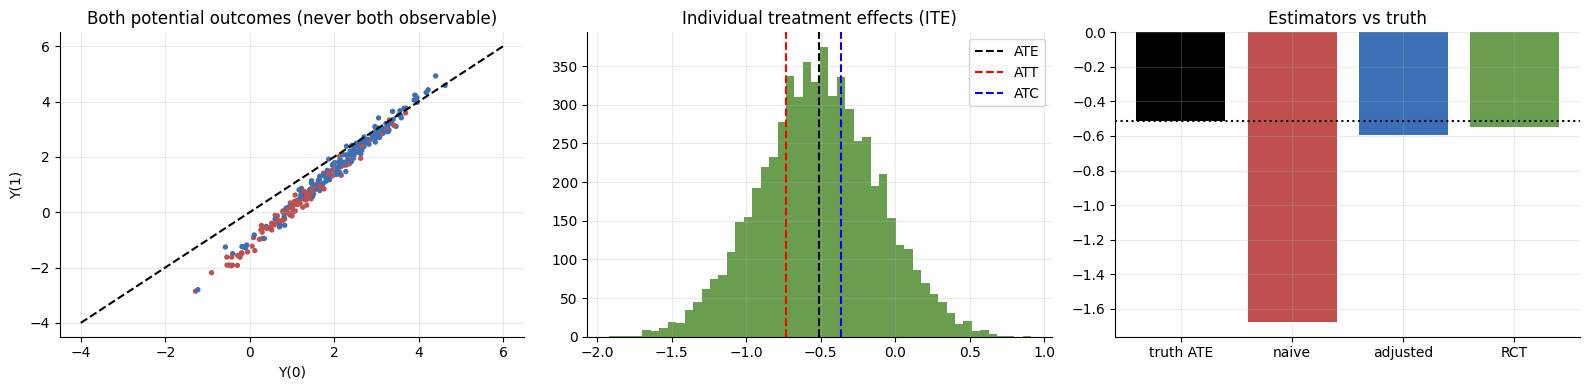

In [3]:
n = 6000
u = rng.normal(size=n)                                     # confounder (think: rurality)
p_t = 1 / (1 + np.exp(-(1.2 * u - .5)))                    # rural units are treated more often
T = (rng.random(n) < p_t).astype(int)
tau = -0.5 - 0.4 * u                                       # heterogeneous true effect (ITE)
Y0 = 2 - 1.0 * u + rng.normal(0, .5, n); Y1 = Y0 + tau
Y = np.where(T == 1, Y1, Y0)
ate, att, atc = tau.mean(), tau[T == 1].mean(), tau[T == 0].mean()
naive = Y[T == 1].mean() - Y[T == 0].mean()
adj = smf.ols("Y ~ T + u", pd.DataFrame({"Y": Y, "T": T, "u": u})).fit().params["T"]
rct_T = rng.integers(0, 2, n); Y_rct = np.where(rct_T == 1, Y1, Y0); rct = Y_rct[rct_T == 1].mean() - Y_rct[rct_T == 0].mean()
print(pd.Series({"true ATE": ate, "true ATT": att, "true ATC": atc, "naive diff (confounded)": naive, "regression adjusting for u": adj, "randomised (RCT)": rct}).round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(Y0[:300], Y1[:300], s=8, c=np.where(T[:300] == 1, "#c0504d", "#3b6fb6")); ax[0].plot([-4, 6], [-4, 6], "k--"); ax[0].set(xlabel="Y(0)", ylabel="Y(1)", title="Both potential outcomes (never both observable)")
ax[1].hist(tau, bins=50, color="#6a9e4f"); [ax[1].axvline(v, ls="--", color=c, label=l) for v, c, l in ((ate, "k", "ATE"), (att, "r", "ATT"), (atc, "b", "ATC"))]; ax[1].legend(); ax[1].set_title("Individual treatment effects (ITE)")
est = pd.Series({"truth ATE": ate, "naive": naive, "adjusted": adj, "RCT": rct}); ax[2].bar(est.index, est.values, color=["k", "#c0504d", "#3b6fb6", "#6a9e4f"]); ax[2].axhline(ate, color="k", ls=":"); ax[2].set_title("Estimators vs truth")
plt.tight_layout(); plt.show()

**Comment:** the true ATE is -0.51 but ATT (-0.73) and ATC (-0.36) differ because effects vary with `u` and treated units differ from controls. The naive difference (-1.68) is badly biased by confounding; adjusting for `u` (-0.59) or randomising (-0.55) lands close to the truth.

## 4 · A/B testing (randomisation) and its limits

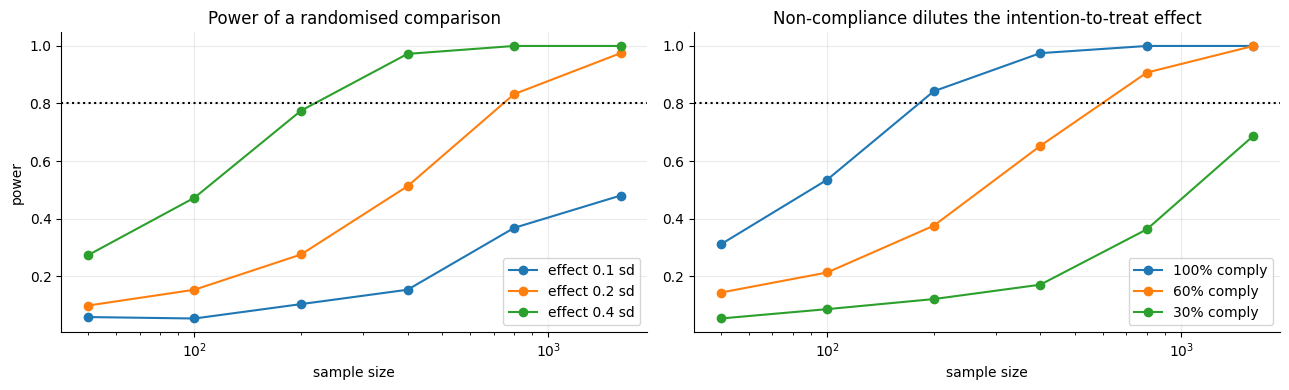

In [4]:
def power(n, eff, comply=1.0, sd=1.0, reps=400):
    hits = 0
    for _ in range(reps):
        z = rng.integers(0, 2, n); took = (rng.random(n) < comply) & (z == 1)
        y_ = rng.normal(0, sd, n) + eff * took
        hits += stats.ttest_ind(y_[z == 1], y_[z == 0]).pvalue < .05
    return hits / reps
ns = [50, 100, 200, 400, 800, 1600]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for eff in (.1, .2, .4): ax[0].plot(ns, [power(n, eff) for n in ns], "o-", label=f"effect {eff} sd")
ax[0].axhline(.8, color="k", ls=":"); ax[0].set_xscale("log"); ax[0].set(xlabel="sample size", ylabel="power", title="Power of a randomised comparison"); ax[0].legend()
for c in (1.0, .6, .3): ax[1].plot(ns, [power(n, .4, comply=c) for n in ns], "o-", label=f"{int(100 * c)}% comply")
ax[1].axhline(.8, color="k", ls=":"); ax[1].set_xscale("log"); ax[1].set(xlabel="sample size", title="Non-compliance dilutes the intention-to-treat effect"); ax[1].legend()
plt.tight_layout(); plt.show()

**Comment:** randomisation removes confounding by design, but (1) small effects need many units, (2) non-compliance dilutes the measured effect, (3) **it is impossible here**: we cannot randomly assign tribal status or rurality to a tract, and (4) SUTVA can fail (neighbouring tracts share mapping effort, so one tract's treatment can spill over to another).

## 5 · The adjustment formula on real data
`E[Y | do(T=t)] = sum_z E[Y | T=t, Z=z] P(Z=z)`. Here `Z` = region x rural stratum, and we only use strata with at least 10 tracts of *both* groups (the overlap population).

naive difference                 : -0.397
standardised ATE (overlap strata): -0.061   95% CI [-0.211, +0.127]
standardised ATT                 : -0.039   95% CI [-0.126, +0.062]
strata used: 5 of 10;  tribal tracts covered: 853 of 874


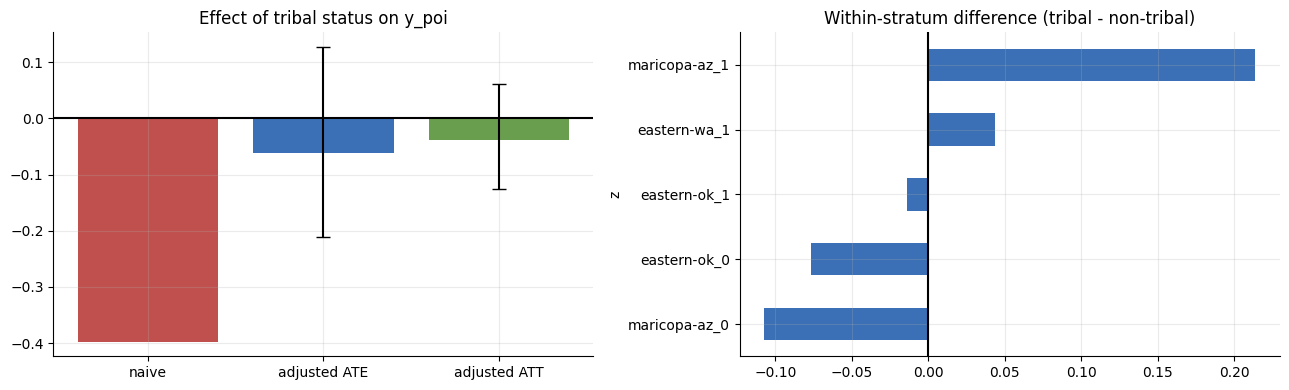

In [5]:
d = f.dropna(subset=["y_poi"]).copy(); d["z"] = d.region + "_" + d.rural.astype(str)
MIN = 10
def estimates(b):
    c_ = b.groupby(["z", "tribal"]).y_poi.agg(["size", "mean"]).unstack()
    sz = c_["size"].dropna()
    ok = sz.index[(sz >= MIN).all(axis=1)]
    diff = (c_["mean"][1] - c_["mean"][0]).loc[ok]
    w_all = b.z.value_counts().loc[ok]; w_t = c_["size"][1].loc[ok]
    return float((diff * w_all / w_all.sum()).sum()), float((diff * w_t / w_t.sum()).sum()), diff
naive = d[d.tribal == 1].y_poi.mean() - d[d.tribal == 0].y_poi.mean()
ate, att, diff = estimates(d)
boots = np.array([estimates(d.sample(len(d), replace=True, random_state=int(rng.integers(1e9))))[:2] for _ in range(300)])
(a_lo, a_hi), (t_lo, t_hi) = np.percentile(boots[:, 0], [2.5, 97.5]), np.percentile(boots[:, 1], [2.5, 97.5])
print(f"naive difference                 : {naive:+.3f}")
print(f"standardised ATE (overlap strata): {ate:+.3f}   95% CI [{a_lo:+.3f}, {a_hi:+.3f}]")
print(f"standardised ATT                 : {att:+.3f}   95% CI [{t_lo:+.3f}, {t_hi:+.3f}]")
print(f"strata used: {len(diff)} of {d.z.nunique()};  tribal tracts covered: {d[d.z.isin(diff.index) & (d.tribal == 1)].shape[0]} of {int(d.tribal.sum())}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(["naive", "adjusted ATE", "adjusted ATT"], [naive, ate, att], color=["#c0504d", "#3b6fb6", "#6a9e4f"])
ax[0].errorbar([1, 2], [ate, att], yerr=[[ate - a_lo, att - t_lo], [a_hi - ate, t_hi - att]], fmt="none", color="k", capsize=5); ax[0].axhline(0, color="k"); ax[0].set_title("Effect of tribal status on y_poi")
diff.sort_values().plot.barh(ax=ax[1], color="#3b6fb6"); ax[1].axvline(0, color="k"); ax[1].set_title("Within-stratum difference (tribal - non-tribal)")
plt.tight_layout(); plt.show()

**Comment:** adjusting for region and rurality shrinks the naive gap of -0.40 to about -0.06 (ATE) and -0.04 (ATT), and both 95% intervals include 0. Under this adjustment set, most of the raw tribal gap is explained by where those tracts are, not by tribal status itself. Only 5 of 10 strata have enough tracts of both groups (Texas is dropped), but they still cover 853 of the 874 tribal tracts. The right panel shows the within-stratum differences are not identical (heterogeneity, notebook 13).

## 6 · Structural causal models: fork, chain, collider; d-separation; back-door and front-door

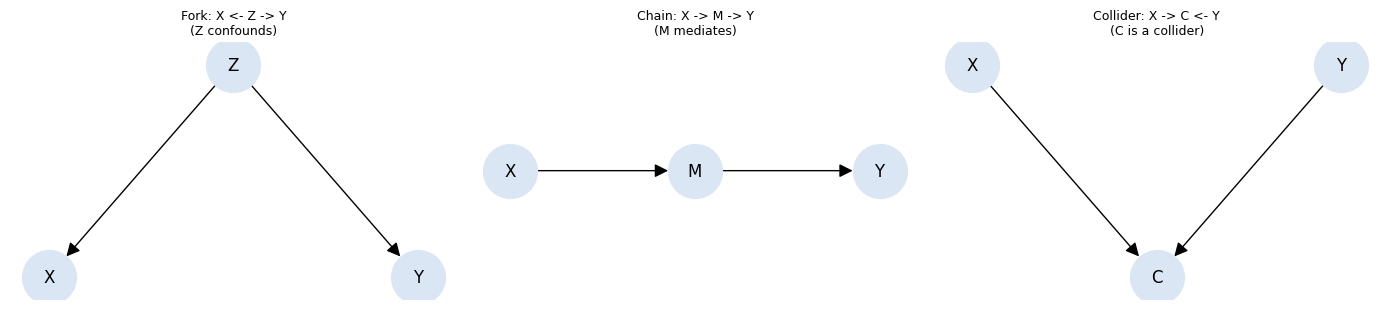

structure  corr(X,Y)  corr(X,Y | middle node)                             rule
     fork      0.507                   -0.000 dependent -> independent given Z
    chain      0.576                   -0.000 dependent -> independent given M
 collider      0.000                   -0.497 independent -> DEPENDENT given C


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
shapes = {"Fork: X <- Z -> Y\n(Z confounds)": [("Z", "X"), ("Z", "Y")], "Chain: X -> M -> Y\n(M mediates)": [("X", "M"), ("M", "Y")], "Collider: X -> C <- Y\n(C is a collider)": [("X", "C"), ("Y", "C")]}
pos = {"Z": (.5, 1), "X": (0, 0), "Y": (1, 0), "M": (.5, 0), "C": (.5, -1)}
for a_, (ttl, edges) in zip(ax, shapes.items()):
    G = nx.DiGraph(edges); nx.draw(G, {k: pos[k] for k in G}, ax=a_, with_labels=True, node_color="#dbe6f5", node_size=1500, arrowsize=20); a_.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()
# simulate each structure: marginal vs conditional dependence
N = 20000; z = rng.normal(size=N)
X1, Y1_ = z + rng.normal(size=N), z + rng.normal(size=N)                       # fork
X2 = rng.normal(size=N); M2 = X2 + rng.normal(size=N); Y2 = M2 + rng.normal(size=N)   # chain
X3, Y3 = rng.normal(size=N), rng.normal(size=N); C3 = X3 + Y3 + rng.normal(size=N)    # collider
resid = lambda a, b: a - np.polyval(np.polyfit(b, a, 1), b)
rows = [("fork", np.corrcoef(X1, Y1_)[0, 1], np.corrcoef(resid(X1, z), resid(Y1_, z))[0, 1], "dependent -> independent given Z"),
        ("chain", np.corrcoef(X2, Y2)[0, 1], np.corrcoef(resid(X2, M2), resid(Y2, M2))[0, 1], "dependent -> independent given M"),
        ("collider", np.corrcoef(X3, Y3)[0, 1], np.corrcoef(resid(X3, C3), resid(Y3, C3))[0, 1], "independent -> DEPENDENT given C")]
print(pd.DataFrame(rows, columns=["structure", "corr(X,Y)", "corr(X,Y | middle node)", "rule"]).round(3).to_string(index=False))

**Comment:** conditioning on a fork's cause or a chain's mediator *blocks* the path; conditioning on a collider *opens* one (a partial correlation of about -0.5 appears from nothing). This is why 'control for everything' is wrong: adjusting for a collider (or a mediator, when you want the total effect) introduces bias.

{}                                False
{Urbanity}                        False
{Region}                          False
{Region, Urbanity}                 True
{Region, Urbanity, Income_SVI}    False


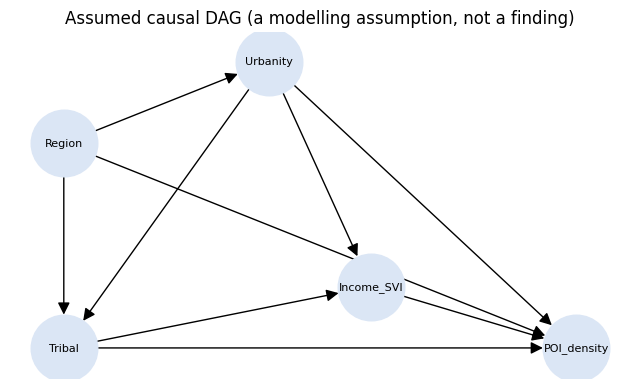

In [7]:
# Our problem as a DAG, and a mechanical back-door check using d-separation
G = nx.DiGraph([("Region", "Tribal"), ("Region", "Urbanity"), ("Urbanity", "Tribal"), ("Region", "POI_density"), ("Urbanity", "POI_density"),
                ("Tribal", "Income_SVI"), ("Income_SVI", "POI_density"), ("Tribal", "POI_density"), ("Urbanity", "Income_SVI")])
def backdoor_ok(G, t, y, Z):
    H = G.copy(); H.remove_edges_from(list(G.out_edges(t)))            # keep only back-door paths
    return nx.is_d_separator(H, {t}, {y}, set(Z)) and not (set(Z) & nx.descendants(G, t))
cands = {"{}": [], "{Urbanity}": ["Urbanity"], "{Region}": ["Region"], "{Region, Urbanity}": ["Region", "Urbanity"], "{Region, Urbanity, Income_SVI}": ["Region", "Urbanity", "Income_SVI"]}
print(pd.Series({k: backdoor_ok(G, "Tribal", "POI_density", v) for k, v in cands.items()}, name="valid back-door set?").to_string())
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = {"Region": (0, 1), "Urbanity": (1, 1.4), "Tribal": (0, 0), "Income_SVI": (1.5, .3), "POI_density": (2.5, 0)}
nx.draw(G, pos, ax=ax, with_labels=True, node_color="#dbe6f5", node_size=2300, font_size=8, arrowsize=18); ax.set_title("Assumed causal DAG (a modelling assumption, not a finding)"); plt.show()

**Comment:** {Region, Urbanity} blocks every back-door path from Tribal to POI density without touching a descendant of Tribal, so it is a valid adjustment set under this DAG. Adding Income/SVI (a mediator) is invalid for the total effect, and omitting Urbanity or Region leaves a confounding path open. A different DAG means different conclusions, so the DAG should be argued, not assumed silently.

In [8]:
# Front-door criterion: T -> M -> Y with an UNOBSERVED confounder U of T and Y. Back-door adjustment is impossible; the front-door works.
N = 60000; U = rng.normal(size=N)
T = (rng.random(N) < 1 / (1 + np.exp(-1.5 * U))).astype(int)
M = (rng.random(N) < np.where(T == 1, .8, .2)).astype(int)                      # mediator caused only by T
Y = 2.0 * M + 1.5 * U + rng.normal(size=N)                                      # true effect of T on Y = 2 * (0.8 - 0.2) = 1.2
df_ = pd.DataFrame({"T": T, "M": M, "Y": Y})
naive = df_[df_["T"] == 1].Y.mean() - df_[df_["T"] == 0].Y.mean()
# front-door: E[Y|do(t)] = sum_m P(m|t) sum_t' E[Y|t',m] P(t')
pt = df_["T"].value_counts(normalize=True); EY = df_.groupby(["T", "M"]).Y.mean(); PM = df_.groupby("T").M.mean()
def do(t): return sum((PM[t] if m == 1 else 1 - PM[t]) * sum(EY[(tp, m)] * pt[tp] for tp in (0, 1)) for m in (0, 1))
print(f"true effect 1.20 | naive {naive:.2f} | front-door {do(1) - do(0):.2f}")

true effect 1.20 | naive 2.80 | front-door 1.19


**Comment:** with a hidden confounder the naive estimate is off, but the front-door formula recovers the true 1.2 because the whole effect flows through an observed mediator that is not itself confounded. Identification, not sample size, is what removes the bias.

## 7 · Essential assumptions, checked on the real data
Exchangeability (no unmeasured confounding) is untestable; **positivity (overlap)** can be checked. SUTVA / consistency are design arguments.

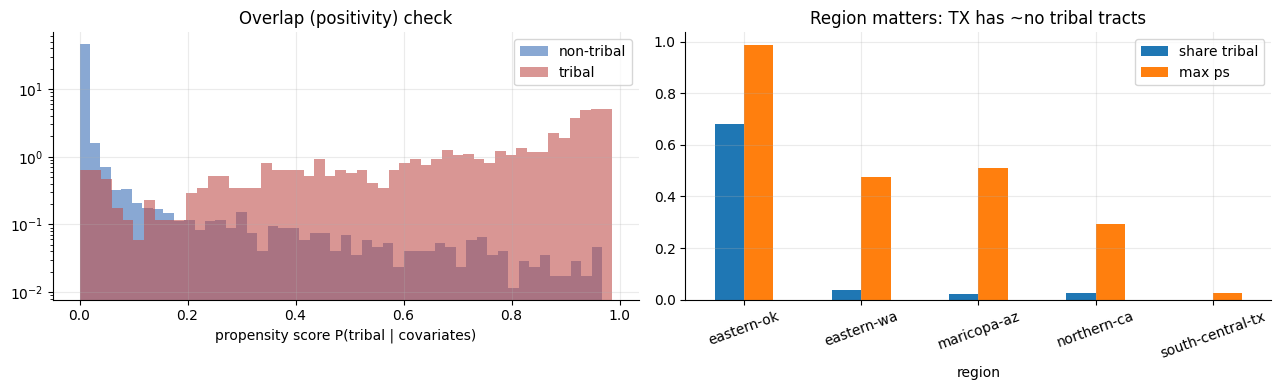

tribal tracts with ps<0.05: 3.1% | non-tribal with ps>0.5: 1.8%


In [9]:
d = f.dropna(subset=["svi", "log_pop_density"]).copy()
Xp = pd.concat([d[["rural", "log_pop_density", "svi", "cvi", "log_area_km2"]].fillna(d[["cvi"]].median().iloc[0]), pd.get_dummies(d.region, drop_first=True, dtype=float)], axis=1)
Xp = (Xp - Xp.mean()) / Xp.std()
ps = LogisticRegression(max_iter=1000).fit(Xp, d.tribal).predict_proba(Xp)[:, 1]
d["ps"] = ps
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t, c, l in ((0, "#3b6fb6", "non-tribal"), (1, "#c0504d", "tribal")): ax[0].hist(ps[d.tribal == t], bins=50, alpha=.6, color=c, label=l, density=True)
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_xlabel("propensity score P(tribal | covariates)"); ax[0].set_title("Overlap (positivity) check")
d.groupby("region").apply(lambda g: pd.Series({"share tribal": g.tribal.mean(), "max ps": g.ps.max()})).plot.bar(ax=ax[1], rot=20); ax[1].set_title("Region matters: TX has ~no tribal tracts")
plt.tight_layout(); plt.show()
print(f"tribal tracts with ps<0.05: {(ps[d.tribal == 1] < .05).mean():.1%} | non-tribal with ps>0.5: {(ps[d.tribal == 0] > .5).mean():.1%}")

**Comment:** the propensity histogram is on a log axis: most non-tribal tracts sit near 0 (Texas, Arizona cities), where no comparable tribal tract exists, and only 3.1% of tribal tracts have a score below 0.05. Causal claims for the far-from-tribal tracts would be extrapolation, so notebook 12 restricts to the overlap region.

**Assumption checklist:** (1) *Exchangeability*: all common causes of tribal status and mapping coverage measured, which is doubtful (history, land tenure and funding are not in the data). (2) *Positivity*: partly violated, shown above. (3) *SUTVA*: doubtful, since neighbouring tracts share OSM contributors. (4) *Consistency*: 'tribal' bundles legal reservations and statistical areas (OTSAs), so treatment is not one well-defined intervention.